# Deep Learning / NLP Text Classifier with PyTorch

**Task:** Binary SMS spam detection (ham vs spam). **Data:** synthetic educational dataset; see README for limitations.

In [1]:
import json, random, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
ROOT = Path.cwd()
if not (ROOT / 'data' / 'sms_messages.jsonl').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data' / 'sms_messages.jsonl').exists(), 'Open notebook from project directory.'
(ROOT / 'models').mkdir(exist_ok=True)
(ROOT / 'figures').mkdir(exist_ok=True)
device = torch.device('cpu')  # reproducible and compatible with most machines
print('PyTorch:', torch.__version__, '| device:', device)

PyTorch: 2.10.0+cpu | device: cpu


## 1. Load and inspect labeled SMS messages

In [2]:
with (ROOT / 'data' / 'sms_messages.jsonl').open(encoding='utf-8') as f:
    df = pd.DataFrame(json.loads(line) for line in f)
print('Rows:', len(df), '| Classes:', df.label.value_counts().to_dict())
display(df.head())

Rows: 720 | Classes: {'ham': 360, 'spam': 360}


,text,label
0,Thank you for the update about cricket practic...,ham
1,Mom asked if you can pick up snacks on your wa...,ham
2,"Hi Ravi, I reached campus safely",ham
3,Thank you for the update about study group. Se...,ham
4,Your account will be suspended. Verify your de...,spam


## 2. Split before vectorizing (avoid data leakage)

In [3]:
train_val, test = train_test_split(df, test_size=0.15, random_state=SEED, stratify=df.label)
train, val = train_test_split(train_val, test_size=0.17647, random_state=SEED, stratify=train_val.label)
vectorizer = TfidfVectorizer(lowercase=True, strip_accents='unicode', ngram_range=(1, 2), max_features=2000, sublinear_tf=True)
X_train = vectorizer.fit_transform(train.text).toarray().astype('float32')
X_val = vectorizer.transform(val.text).toarray().astype('float32')
X_test = vectorizer.transform(test.text).toarray().astype('float32')
labels = {'ham': 0, 'spam': 1}
y_train = train.label.map(labels).to_numpy(dtype='int64')
y_val = val.label.map(labels).to_numpy(dtype='int64')
y_test = test.label.map(labels).to_numpy(dtype='int64')
print('Train/validation/test:', len(train), len(val), len(test), '| Features:', X_train.shape[1])

Train/validation/test: 504 108 108 | Features: 683


## 3. Build multi-layer neural network with dropout and batch normalization

In [4]:
class SpamNet(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.35),
            nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.25),
            nn.Linear(64, 2)
        )
    def forward(self, x):
        return self.network(x)

model = SpamNet(X_train.shape[1]).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
train_loader = DataLoader(TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val)), batch_size=64)
print(model)

SpamNet(
  (network): Sequential(
    (0): Linear(in_features=683, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.35, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.25, inplace=False)
    (8): Linear(in_features=64, out_features=2, bias=True)
  )
)


## 4. Train with validation monitoring and early stopping

In [5]:
def evaluate(loader):
    model.eval()
    total_loss, correct, count = 0., 0, 0
    with torch.no_grad():
        for x, y in loader:
            logits = model(x.to(device))
            total_loss += criterion(logits, y.to(device)).item() * len(y)
            correct += (logits.argmax(dim=1).cpu() == y).sum().item()
            count += len(y)
    return total_loss/count, correct/count

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_loss = float('inf'); best_state = None; patience = 5; stale = 0
for epoch in range(1, 31):
    model.train()
    for x, y in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(x.to(device)), y.to(device))
        loss.backward()
        optimizer.step()
    tr_loss, tr_acc = evaluate(train_loader)
    va_loss, va_acc = evaluate(val_loader)
    for k, v in zip(history, [tr_loss, va_loss, tr_acc, va_acc]):
        history[k].append(v)
    print(f'Epoch {epoch:02d} | train loss={tr_loss:.4f} acc={tr_acc:.3f} | val loss={va_loss:.4f} acc={va_acc:.3f}')
    if va_loss < best_loss - 1e-4:
        best_loss = va_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        stale = 0
    else:
        stale += 1
        if stale >= patience:
            print('Early stopping triggered.'); break
model.load_state_dict(best_state)
torch.save({'state_dict': model.state_dict(), 'input_dim': X_train.shape[1]}, ROOT / 'models' / 'spam_classifier.pt')
with (ROOT / 'models' / 'tfidf_vectorizer.pkl').open('wb') as f:
    pickle.dump(vectorizer, f)
(ROOT / 'models' / 'label_mapping.json').write_text(json.dumps(labels, indent=2))
print('Best validation loss:', round(best_loss, 4))

Epoch 01 | train loss=0.6571 acc=0.619 | val loss=0.6589 acc=0.593
Epoch 02 | train loss=0.4877 acc=1.000 | val loss=0.4903 acc=1.000


Epoch 03 | train loss=0.2160 acc=1.000 | val loss=0.2198 acc=1.000
Epoch 04 | train loss=0.0542 acc=1.000 | val loss=0.0560 acc=1.000
Epoch 05 | train loss=0.0175 acc=1.000 | val loss=0.0181 acc=1.000


Epoch 06 | train loss=0.0105 acc=1.000 | val loss=0.0109 acc=1.000
Epoch 07 | train loss=0.0076 acc=1.000 | val loss=0.0079 acc=1.000


Epoch 08 | train loss=0.0060 acc=1.000 | val loss=0.0062 acc=1.000
Epoch 09 | train loss=0.0047 acc=1.000 | val loss=0.0048 acc=1.000


Epoch 10 | train loss=0.0037 acc=1.000 | val loss=0.0037 acc=1.000
Epoch 11 | train loss=0.0029 acc=1.000 | val loss=0.0030 acc=1.000


...

Epoch 21 | train loss=0.0010 acc=1.000 | val loss=0.0010 acc=1.000
Epoch 22 | train loss=0.0009 acc=1.000 | val loss=0.0009 acc=1.000


Epoch 23 | train loss=0.0008 acc=1.000 | val loss=0.0008 acc=1.000
Epoch 24 | train loss=0.0007 acc=1.000 | val loss=0.0008 acc=1.000


Epoch 25 | train loss=0.0007 acc=1.000 | val loss=0.0007 acc=1.000
Epoch 26 | train loss=0.0007 acc=1.000 | val loss=0.0007 acc=1.000
Epoch 27 | train loss=0.0006 acc=1.000 | val loss=0.0006 acc=1.000


Epoch 28 | train loss=0.0005 acc=1.000 | val loss=0.0005 acc=1.000
Epoch 29 | train loss=0.0005 acc=1.000 | val loss=0.0005 acc=1.000


Epoch 30 | train loss=0.0005 acc=1.000 | val loss=0.0005 acc=1.000
Best validation loss: 0.0006


## 5. Plot loss and accuracy convergence curves

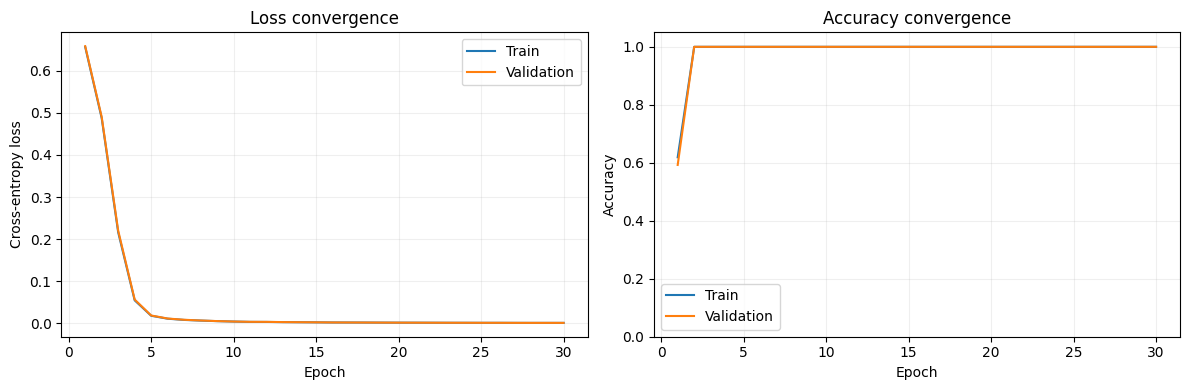

In [6]:
epochs = np.arange(1, len(history['train_loss'])+1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(epochs, history['train_loss'], label='Train'); ax[0].plot(epochs, history['val_loss'], label='Validation')
ax[0].set(title='Loss convergence', xlabel='Epoch', ylabel='Cross-entropy loss'); ax[0].legend(); ax[0].grid(alpha=0.2)
ax[1].plot(epochs, history['train_acc'], label='Train'); ax[1].plot(epochs, history['val_acc'], label='Validation')
ax[1].set(title='Accuracy convergence', xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1.05)); ax[1].legend(); ax[1].grid(alpha=0.2)
plt.tight_layout(); plt.savefig(ROOT / 'figures' / 'training_curves.png', dpi=150); plt.show()

## 6. Evaluate on held-out test set

Test accuracy: 1.0
              precision    recall  f1-score   support

         ham       1.00      1.00      1.00        54
        spam       1.00      1.00      1.00        54

    accuracy                           1.00       108
   macro avg       1.00      1.00      1.00       108
weighted avg       1.00      1.00      1.00       108



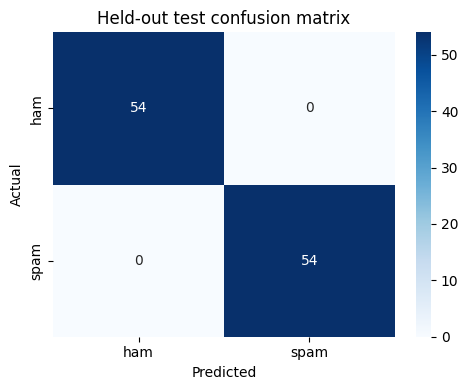

In [7]:
model.eval()
with torch.no_grad():
    test_probs = torch.softmax(model(torch.from_numpy(X_test)), dim=1).numpy()
preds = test_probs.argmax(axis=1)
print('Test accuracy:', round(accuracy_score(y_test, preds), 4))
print(classification_report(y_test, preds, target_names=['ham', 'spam'], zero_division=0))
cm = confusion_matrix(y_test, preds)
plt.figure(figsize=(5, 4)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['ham','spam'], yticklabels=['ham','spam'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Held-out test confusion matrix')
plt.tight_layout(); plt.savefig(ROOT / 'figures' / 'confusion_matrix.png', dpi=150); plt.show()

## 7. Inference on new sample messages with confidence scores

**Caution:** Softmax confidence is not a calibrated real-world probability.

In [8]:
def predict_messages(messages):
    features = vectorizer.transform(messages).toarray().astype('float32')
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(torch.from_numpy(features)), dim=1).numpy()
    return pd.DataFrame({'message': messages,
                         'prediction': ['spam' if i == 1 else 'ham' for i in probs.argmax(axis=1)],
                         'confidence': np.round(probs.max(axis=1), 4),
                         'spam_probability': np.round(probs[:, 1], 4)})

samples = [
    'Congratulations! Claim your free gift card now at reward.example',
    'Hey Ravi, can we meet at the library at 4 PM?',
    'Limited time discount! Click promo.example to claim your voucher',
    'Please share the project notes after class tomorrow.'
]
display(predict_messages(samples))

,message,prediction,confidence,spam_probability
0,Congratulations! Claim your free gift card now...,spam,0.9991,0.9991
1,"Hey Ravi, can we meet at the library at 4 PM?",ham,0.9969,0.0031
2,Limited time discount! Click promo.example to ...,spam,0.9986,0.9986
3,Please share the project notes after class tom...,ham,0.9989,0.0011


## Conclusion

This educational pipeline demonstrates TF-IDF + PyTorch neural classification, BatchNorm, Dropout, early stopping, held-out evaluation and confidence-based inference. **Synthetic template overlap limits external validity.** Replace with real labeled data and perform leakage-resistant evaluation before making real-world performance claims.